# 1. 자연어 처리(NLP) 기초
- 자연어 처리 (Natural Language Processing, NLP)는 컴퓨터가 사람이 사용하는 언어를 처리하고 이해하고 생성할 수 있도록 만드는 인공지능 분야
- 과거에는 단어의 빈도와 통계적인 특징을 이용하는 방법이 많이 사용되었지만, 현재는 Transformer와 대규모 언어 모델(LLM)을 중심으로 자연어 처리가 발전하고 있음

```
Text > Tokenization > Token > Token ID > Padding / Attention Mask > Embedding > Neural Network > Transformer > LLM
```

In [18]:
import torch 

In [19]:
text = "나는 자연어를 공부한다"

# tokenization
tokens = text.split()  # 원래는 split() 사용하지 않음

# 단어 사전
# 단어들 숫자화
vocab = {"<PAD>":0, "<UNK>":1, "나는":2, "자연어를":3, "공부한다":4}

# Token ID
token_ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

input_ids = torch.tensor(token_ids, dtype=torch.long)

# 여기서 2, 3, 4는 의미의 크기가 아니라 단순한 Token 식별 번호
# 이후에 Embedding이 각 번호를 실수 Vector로 바꾸고, 그 Vector를 신경망이 학습
print('원문: ', text)
print('Token: ', tokens)
print("Token ID: ", token_ids)
print("PyTorch Tensor: ", input_ids)
print("dtype: ", input_ids.dtype)

원문:  나는 자연어를 공부한다
Token:  ['나는', '자연어를', '공부한다']
Token ID:  [2, 3, 4]
PyTorch Tensor:  tensor([2, 3, 4])
dtype:  torch.int64


### 1. 자연어 처리란?
- 컴퓨터가 자연어를 처리하는 기술을 자연어 처리라고 함.
- 대표적인 자연어 처리 작업에는 아래와 같은 것들이 있다.
    - 텍스트 분류
    - 감정 분석
    - 문서 요약
    - 기계 번역
    - 질의 응답
    - 정보 검색
    - 챗봇
    - 문장 생성
    - RAG
    - LLM 기반 Agent

> 최근에는 자연어 처리 기술이 이미지, 음성, 영상 등의 데이터와 결합되면서 Multimodal AI로 확장

### 2. 컴퓨터는 문장을 그대로 이해하지 못함
- 컴퓨터의 신경망 모델은 문자열 자체를 그대로 계산하지 않음
- 자연어를 모델에 입력하기 위해서는 숫자로 변환하는 과정이 필요

```
"오늘 날씨가 정말 좋다" > Tokenization > Token > Token ID > Embedding > Vector > Neural Network
```

> 자연어 처리에서 가장 중요한 시작점은 결국 "문장을 어떻게 나누고, 그것을 어떻게 숫자로 표현할것인가?" 이다.

### 3. Corpus와 Document

1. Corpus
    - Corpus(말뭉치)는 자연어 처리에서 분석하거나 학습하기 위해 수집한 전체 텍스트 데이터의 집합

2. Document
    - Corpus를 구성하는 각각의 텍스트 데이터
    - Document라고 해서 반드시 긴 문서를 의미하는 것은 아님
    - 상황에 따라 예) 뉴스 기사 하나, 리뷰 하나, 댓글 하나, 문장 하나

### 4. Tokenization
- Tokenization은 텍스트를 모델이 처리할 수 있는 작은 단위인 Token으로 나누는 과정
- Token은 반드시 단어 하나를 의미하지는 않음
- Token의 단위는 아래처럼 다양할 수 있음
    - 예) 문장, 단어, 형태소, 문자, Subword

- > 과거에는 영어에서 공백을 기준으로 나누거나 한국어에서는 형태소 분석기를 이용하는 방법을 많이 사용
- > 현대의 Transformer 기반 NLP에서는 Subword Tokenization이 매우 중요

# 2. Hugging Face
- 자연어 처리뿐 아니라 이미지, 음성, 영상, Multimodal AI 모델을 공유하고 사용하는 데 필요한 여러 도구와 서비스를 제공하는 AI 생태계이자 회사 이름

In [20]:
from transformers import AutoTokenizer

In [21]:
# from_pretrained: Hub의 "klue/bert-base" Repository에서 Tokenizer 설정과 Vocabulary를 불러옴
tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")

# Sample Text
text = "자연어 처리를 공부합니다."

# Tokenize
tokens = tokenizer.tokenize(text)
print("Token: ", tokens)

# Assign token ID to tokenized tokens
token_ids = tokenizer.convert_tokens_to_ids(tokens)
print("token ID: ", token_ids)

Token:  ['자연', '##어', '처리', '##를', '공부', '##합니다', '.']
token ID:  [3941, 2051, 4211, 2138, 4244, 11800, 18]


### 1. Vocabulary
- Vocabulary는 Tokenizer가 사용하는 Token들의 집합
- 각 Token에는 고유한 정수 ID가 할당됨
- 중요한 것은 Token ID 자체는 언어적인 의미가 없다는 것

In [22]:
# [PAD], [UNK], [CLS], [SEP] 처럼 특별한 목적으로 사용하는 Token을 Special Token이라고 함
tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")
print("Vocabulary Sizez: ", tokenizer.vocab_size)
print("[PAD] ID: ", tokenizer.pad_token_type_id)
print("[UNK] ID: ", tokenizer.unk_token_id)
print("[CLS] ID: ", tokenizer.cls_token_id)
print("[SEP] ID: ", tokenizer.sep_token_id)

Vocabulary Sizez:  32000
[PAD] ID:  0
[UNK] ID:  1
[CLS] ID:  2
[SEP] ID:  3


### 2. OOV (Out-Of-Vocabulary)
- OOV(Out-Of-Vocabulary)는 Vocabulary에 존재하지 않는 Token이 입력되는 문제 (신조어 등등)
- 과거의 단어 단위 Vocabulary에서는 처음 보는 단어를 <UNK>와 같은 Unknown Token으로 처리하는 경우가 많았음.
- 현대 NPL에서는 Subword Tokenization을 이용하여 이 문제를 크게 줄임

> 단어 단위 Vocabulary의 OOV 문제는 Subword Tokenizer로 처음 보는 단어를 더 작은 조각으로 나눠 OOV를 크게 줄일 수 있음

In [28]:
vocab = {"<PAD>": 0, "<UNK>": 1, "나는": 2, "파이토치를": 3, "공부한다": 4}
tokens = {"나는", "트랜스포머를", "공부한다"}

token_ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
print(token_ids)

[1, 2, 4]


### 3. Token ID
- Tokenization이 끝나면 각각의 Token을 Vocabulary에 정의된 정수 ID로 변환

```
"오늘 날씨가 좋다" > Tokenization > [Token1, Token2, Token3 ...] > Token ID > [101, 234, 566, 331 ...]
```

In [30]:
# 문장을 토큰 ID와 모델 입력용 Tensor로 변환 (Embedding 전 단계)
tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")

# return_tensors="pt": 결과를 PyTorch Tensor로 반환
# padding=True: Batch 안에서 가장 긴 sequence에 맞춰 짧은 입력을 padding
# truncation=True: 문장이 모델이 처리할 수 있는 최대 입력 길이를 넘으면 잘라냄
encoded = tokenizer("자연어 처리를 공부합니다.", return_tensors="pt", padding=True, truncation=True)

# Token과 Special Token을 정수 ID로 바꾼 Tensor
print(encoded['input_ids'])

# 실제 Token은 1, Padding 위치는 0으로 표시된 Tensor
print(encoded['attention_mask'])

print(type(encoded['input_ids']))
print(encoded['input_ids'].dtype)
# token_type_ids: 일부 BERT계열에서 문장 A와 문장 B를 구분하는 Tensor이며, 모든 모델이 반환하는 것은 아님

# encoded: 단순한 Tensor 하나가 아니라 모델 입력에 필요한 여러 값을 key로 담은 BatchEncoding 객체

tensor([[    2,  3941,  2051,  4211,  2138,  4244, 11800,    18,     3]])
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1]])
<class 'torch.Tensor'>
torch.int64


### 4. Padding
- 문장은 각각 길이가 다름. 이때 Tensor의 크기를 맞추기 위해 짧은 Sequence에 특별한 Padding Token을 추가할 수 있음 (행렬곱을 위해 크기 맞춰야함)

```
문장 1
[15, 23, 51]

문장 2
[73, 18, 94, 21, 55]

Padding 후
[15, 23, 51, 0, 0]   # <PAD>가 0번으로 assign 돼있음
[73, 18, 94, 21, 55]
```

> 0을 \<PAD\>의 ID로 사용했음

In [31]:
from torch.nn.utils.rnn import pad_sequence

In [ ]:
sentence_a = torch.tensor([15, 23, 51], dtype=torch.long)
sentence_b = torch.tensor([73, 18, 94, 21, 55], dtype=torch.long)

# batch_first=True: 결과 차원을 [Batch 크기, Sequence 길이] 순서로 배치 (문장으로 묶인 형태)
padded = pad_sequence([sentence_a, sentence_b], padding_value=0, batch_first=True)

print(padded)
print('Shape: ', padded.shape)

tensor([[15, 23, 51,  0,  0],
        [73, 18, 94, 21, 55]])
Shape:  torch.Size([2, 5])


### 5. Padding과 Attention Mask
- Padding을 추가하면 문제가 생길 수 있음 > 모델 입장에서는 Padding도 하나의 입력 숫자
- 하지만 Padding은 실제 문장의 내용이 아님 > Transformer에서는 Attention Mask를 함께 사용

```
Input IDs
[15, 23, 51, 0, 0]

Attention Mask
[1, 1, 1, 0, 0]

1: 실제 토큰, 
0: 패딩
```

In [38]:
input_ids = torch.tensor([
    [15, 23, 51, 0, 0],
    [73, 18, 94, 21, 55], 
], dtype=torch.long)

attention_mask = (input_ids != 0).long()
print(attention_mask)

tensor([[1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1]])


# 3. 벡터화
- 벡터화는 텍스트 데이터를 숫자 형태로 변환하여 머신러닝 또는 딥러닝 모델에서 처리할 수 있도록 만드는 과정입니다. 
- 이를 위해 단어의 빈도를 기반으로 한 Bag-of-Words(BOW), TF-IDF와 같은 방법부터, 단어 간의 의미적 관계를 학습하는 Word Embedding(단어 임베딩), 문장의 문맥과 구조를 반영하는 Transformer 기반 임베딩(BERT, GPT) 등 다양한 기법이 사용됩니다. 
- 벡터화는 단어, 문장, 문서와 같은 텍스트 데이터의 특징을 수치적으로 표현하며, 단순히 단어의 빈도를 반영하거나 의미적 유사성을 학습하여 벡터 공간에서 단어 간 관계를 나타냅니다. 
- 데이터의 특성과 분석 목적에 따라 적절한 벡터화 기법을 선택하는 것이 중요합니다.

### 1. One-Hot Encoding
- 원-핫 인코딩(One-Hot Encoding)은 텍스트 데이터를 숫자 벡터로 변환하는 가장 단순한 방법 중 하나로, 단어 집합(vocabulary)에 있는 단어들을 고유한 숫자 벡터로 표현합니다.
- 이 방법은 각 단어를 벡터의 한 차원으로 지정하고, 해당 단어에만 1을 넣고 나머지는 0으로 설정합니다. 
- 이를 통해 텍스트 데이터를 컴퓨터가 이해할 수 있는 숫자로 변환합니다. 예를 들어, 단어 집합이 ["I", "love", "Python"]이라면, "love"는 [0, 1, 0]으로 표현됩니다. 
- 이 방법은 단어를 간단하고 직관적으로 표현할 수 있지만, 단어 간의 의미적 관계를 반영하지 못하며, 단어 집합 크기만큼 고차원 희소 벡터를 생성하므로 메모리 낭비가 큽니다.

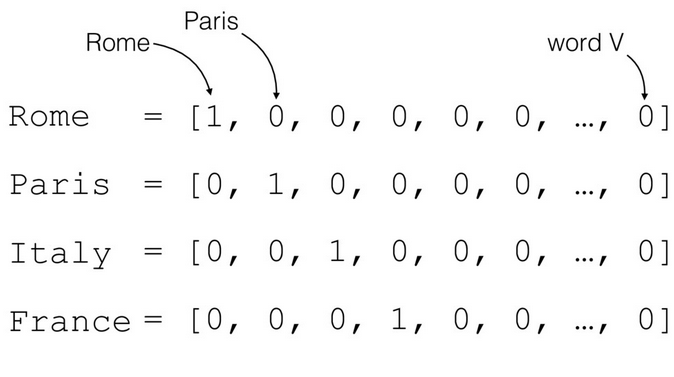

In [39]:
import torch.nn.functional as F

In [42]:
token_id = torch.tensor(2)  # 2번에 해당하는 단어
vocab_size = 5

one_hot = F.one_hot(token_id, num_classes=vocab_size)
print(one_hot)
print(one_hot.shape)  # Vocabulary 크기

tensor([0, 0, 1, 0, 0])
torch.Size([5])


### 희소 벡터
- 희소 벡터(Sparse Vector)는 대부분의 값이 0인 벡터를 의미하며, 자연어 처리에서 원-핫 인코딩(One-Hot Encoding)과 같은 방법으로 단어를 표현할 때 자주 나타납니다. 
- 예를 들어, 단어 집합의 크기가 10,000이라면 각 단어를 표현하는 벡터는 10,000차원이 되고, 이 중 단 하나의 위치만 1이고 나머지는 모두 0으로 채워집니다. 
- 이러한 벡터는 메모리 낭비와 계산 복잡도를 초래하며, 특히 단어 집합이 클수록 문제가 심각해집니다. 
- 이를 해결하기 위해 단어를 저차원의 조밀한 벡터(Dense Vector)로 변환하는 워드 임베딩(Word Embedding) 기법이 자주 사용됩니다.

### 2. Bag of Words (BOW)
- Bag of Words(BOW)는 텍스트 데이터를 벡터화하는 간단한 방법으로, 문장을 구성하는 단어들의 등장 빈도를 기반으로 표현합니다. 
- 각 문장은 단어 집합(vocabulary)의 크기만큼 차원을 가지며, 단어가 해당 문장에 몇 번 나타나는지 그 빈도를 벡터의 값으로 나타냅니다. 
- 예를 들어, 단어 집합이 ["I", "love", "Python"]이고 문장이 "I love Python Python"이라면, 벡터는 [1, 1, 2]로 표현됩니다. 
- 단어의 순서나 문맥은 고려되지 않고 단순히 단어의 빈도만 반영되기 때문에, 문장의 구조나 의미를 표현하는 데는 한계가 있습니다. 
- 하지만 구현이 간단하고 텍스트 데이터를 빠르게 벡터화할 수 있어 자연어 처리의 기초적인 방법으로 널리 사용됩니다. 
- TF-IDF와 같은 확장 기법을 통해 BOW의 단점을 보완하기도 합니다. 

### 3. TF-IDF
- TF-IDF(Term Frequency-Inverse Document Frequency)는 텍스트 데이터에서 단어의 중요도를 측정하는 방법으로, 단어의 빈도(TF)와 역문서 빈도(IDF)를 조합하여 계산됩니다. 
- 단어 빈도(TF)는 특정 문서에서 해당 단어가 얼마나 자주 등장하는지를 나타내고, 
- 역문서 빈도(IDF)는 해당 단어가 다른 문서들에 얼마나 흔하게 등장하는지를 반영하여 중요도를 조정합니다. 
- 이를 통해, 특정 문서에서 자주 등장하면서도 다른 문서에서는 잘 나타나지 않는 단어의 가중치가 높아집니다. 
- 예를 들어, 일반적으로 모든 문서에서 자주 등장하는 단어(예: "the", "is")는 낮은 가중치를 받고, 특정 문서에서만 중요한 단어는 높은 가중치를 받습니다. 
- TF-IDF는 문서의 내용을 잘 나타내는 단어를 식별하고, 텍스트 데이터의 벡터화를 통해 검색 엔진, 텍스트 분류 등의 작업에서 널리 사용됩니다.

> 현재 Transformer 중심의 NLP를 공부 한다면 TF-IDF 공식을 직접 구현하거나 수학적으로 깊게 공부할 필요 없음. 다만 전통적인 텍트스 검색과 머신러닝 기반 텍스트 분류에서 사용하는 방법이라는 개념은 알아두면 좋음

### 4. Word Embedding
- 워드 임베딩(Word Embedding)은 단어를 고차원의 희소 벡터로 표현하는 기존 방식(원-핫 인코딩) 대신, 단어의 의미를 저차원의 밀집 벡터(dense vector)로 변환하는 자연어 처리 기법입니다. 
- 이를 통해 단어 간 유사성과 관계를 벡터 공간에 효율적으로 나타낼 수 있으며, 벡터 간의 거리 또는 방향을 통해 단어의 문맥적 의미를 학습합니다. 
- 대표적인 워드 임베딩 알고리즘으로는 Embedding Layer, Word2Vec, GloVe, FastText 등이 있으며, 
- 이를 사용하면 언어 모델이 문맥을 이해하거나 추론하는 데 필요한 기초적인 언어적 의미를 학습할 수 있습니다.

```
Token ID > Embedding > [0.21, -0.72, 0.13, 0.84, ... ]
```

> Embedding의 중요한 목적은 Token을 신경망이 학습하기 좋은 연속적인 벡터 공간으로 표현하는 것

In [43]:
import torch.nn as nn

In [ ]:
# num_embeddings: Vocabulary 크기
# embedding_dim: Token 하나를 표현할 Vector의 차원
# padding_idx: Padding Token의 ID
embedding = nn.Embedding(num_embeddings=10000, embedding_dim=128, padding_idx=0)
print(embedding)
# Embedding Layer 내부에는 Vocab size * Embedding Dim (10000 * 128)
# 10000개의 Token 각각에 128차원의 Vector가 존재함
print("Embedding Weight Shape: ", embedding.weight.shape)

Embedding(10000, 128, padding_idx=0)
Embedding Weight Shape:  torch.Size([10000, 128])


### nn.Embedding
- Token ID에 해당하는 Vector를 Embedding Table에서 가져오는 Lookup Table

```
1. Token ID
[15, 27, 103]

2. Embedding Table
15번 Vector
27번 Vector
103번 Vector

3. Embedding Vector
```

> 예를 들어 입력 Tensor의 크기가 (batch_size, sequence_length)이고 embedding_dim=128이라면 Embedding을 통과한 후에는 (batch_size, sequence_length, 128)의 크기가 됨. 이 Shape 변화는 Transformer를 공부할 때 매우 중요함

In [52]:
input_ids = torch.tensor([
    [1, 2, 3],
    [4, 5, 6]
], dtype=torch.long)

embedding = nn.Embedding(num_embeddings=10, embedding_dim=4, padding_idx=0)
output = embedding(input_ids)

print("Input Shape: ", input_ids.shape)
print("Output Shape: ", output.shape)
print(output)

Input Shape:  torch.Size([2, 3])
Output Shape:  torch.Size([2, 3, 4])
tensor([[[-1.3975,  1.1767, -0.9126,  0.2653],
         [-0.6207, -2.0065, -2.3890,  0.6961],
         [-0.8548, -0.2332,  0.2714,  0.5838]],

        [[ 0.8621,  1.2700, -0.7515,  0.5814],
         [-0.4711,  0.2916, -1.6309, -0.2123],
         [-0.3389,  1.9419, -0.7059,  1.7879]]], grad_fn=<EmbeddingBackward0>)


- Embedding Vector는 사람이 직접 의미를 입력하는 것이 아님
- 처음에는 초기값으로 시작하고 모델 학습 과정에서 다른 Weight들과 함께 업데이트 됨
```
Embedding > Model > Prediction > Loss > Backpropagation > Embedding Weight Update
```

> 따라서 nn.Embedding의 Weight 역시 학습 가능한 Parameter!

In [57]:
embedding = nn.Embedding(num_embeddings=100, embedding_dim=16, padding_idx=0)
print("Weight Shape: ", embedding.weight.shape)
print("학습 가능 여부: ", embedding.weight.requires_grad)
print("Parameter 수: ", embedding.weight.numel())

Weight Shape:  torch.Size([100, 16])
학습 가능 여부:  True
Parameter 수:  1600


# 4. Word2Vec
- [Word2Vec](https://projector.tensorflow.org/)은 단어를 벡터로 표현하기 위해 개발된 자연어 처리 기법으로, 단어 간의 의미적 유사성을 수치적으로 나타낼 수 있는 임베딩 벡터를 생성합니다. 
- 주로 CBOW(Continuous Bag of Words)와 Skip-gram(GPT가 사용)이라는 두 가지 모델 구조를 사용하며, 
    - CBOW는 주변 단어들을 기반으로 중심 단어를 예측하고, 
    - Skip-gram은 중심 단어를 기반으로 주변 단어들을 예측하는 방식입니다. 
- 이 과정을 통해 학습된 임베딩 벡터는 단어 간의 문맥적 관계를 반영하며, 벡터 공간에서 유사한 의미를 가진 단어들이 서로 가깝게 위치합니다. 
- Word2Vec은 대규모 코퍼스를 활용해 고성능 임베딩을 생성할 수 있으며, 자연어 처리 작업에서 사전 훈련된 임베딩으로 널리 사용됩니다. 벡터가 된 단어들은 연산이 가능합니다.

```
한국에서 서울이라는 관계를 빼고, 그 자리에 도쿄라는 관계를 넣으면 어떤 단어가 가까울까?
(한국의 벡터 - 서울의 벡터 + 도쿄의 벡터)
한국-서울+도쿄 >> 일본/Noun
```

> Word2Vec은 단어를 그냥 번호로 바꾸는 게 아니라, 단어의 의미와 관계가 어느 정도 반영된 숫자의 벡터로 바꿈. 그래서 단어끼리 더하고 빼는 연산도 가능

### 1. CBOW (Continuous Bag of Words)
- CBOW(Continuous Bag of Words)는 자연어 처리에서 단어 임베딩을 학습하기 위해 사용되는 Word2Vec 알고리즘의 한 방법입니다. 
- 이 모델은 주어진 문맥(즉, 중심 단어 주변의 단어들)을 기반으로 중심 단어를 예측하는 방식으로 작동합니다. 
- 예를 들어, 문장에서 특정 단어의 좌우 몇 개 단어를 입력으로 받아 해당 중심 단어를 출력으로 예측하는 구조입니다. 
- 이를 통해 단어 간의 문맥적 관계를 효과적으로 학습할 수 있으며, 단어를 고차원 공간의 벡터로 표현하여 의미적으로 유사한 단어들이 가까운 위치에 있도록 학습됩니다. 
- CBOW는 연산적으로 효율적이며, 대규모 데이터에서 빠르고 안정적으로 임베딩을 생성할 수 있다는 장점이 있습니다.

> 모델은 문맥 단어를 보고 중심 단어를 정확히 예측할 수 있도록 가중치를 학습. 또한, 단어를 임베딩 벡터로 변환해 의미적으로 유사한 단어들이 가까운 위치에 배치되도록 함

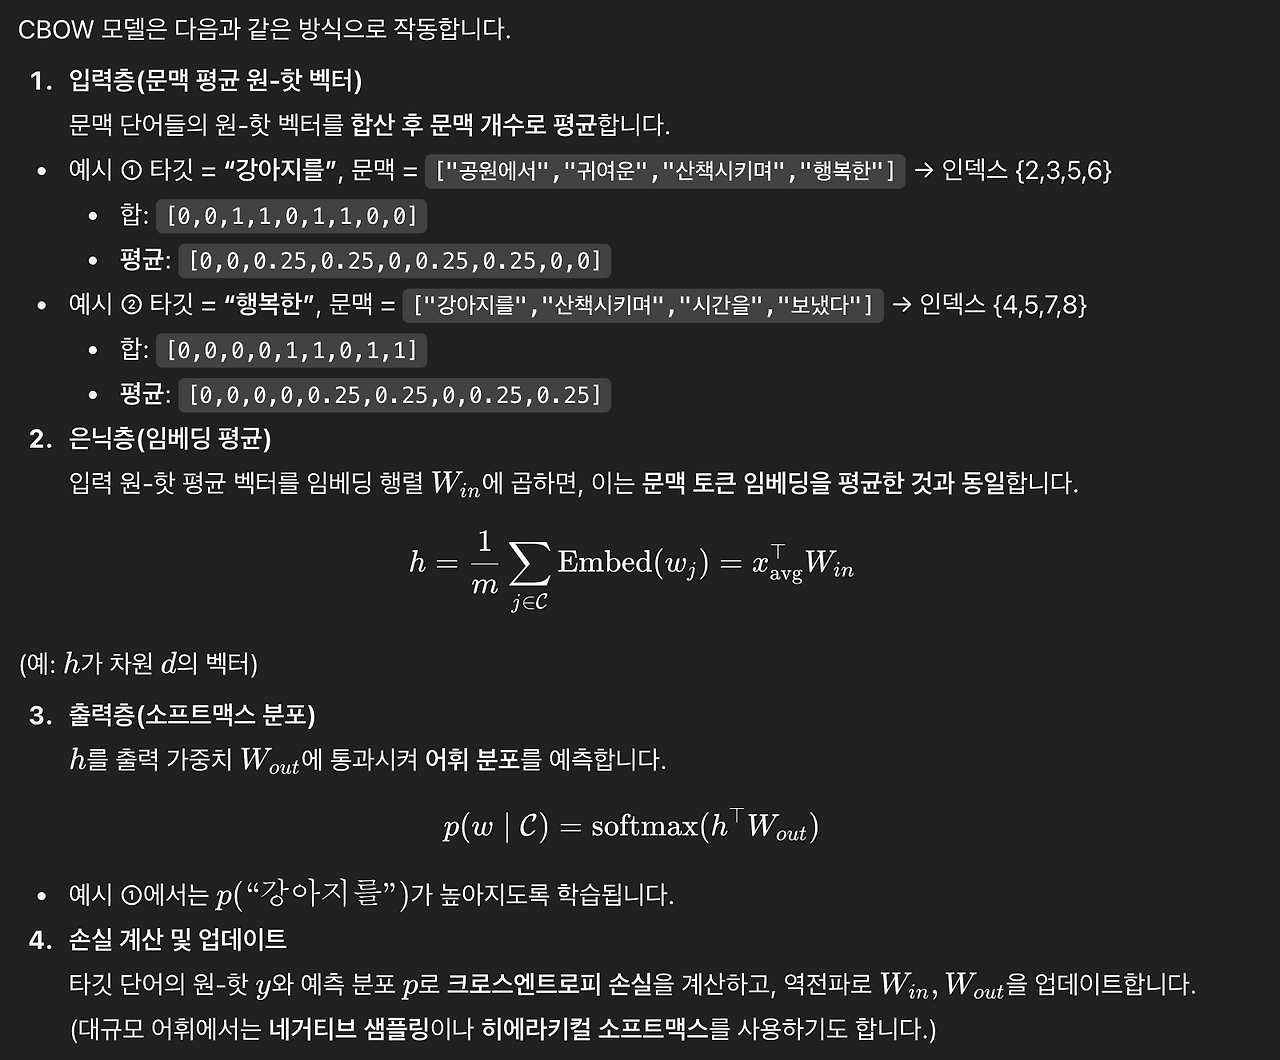

### 2. Skip-gram
- Skip-gram은 Word2Vec 알고리즘의 한 방법으로, 주어진 중심 단어로부터 주변 문맥 단어들을 예측하는 방식으로 작동합니다. 
- 즉, 중심 단어를 입력으로 사용하고, 그 단어를 기준으로 설정된 윈도우 크기 내에 있는 주변 단어들을 출력으로 예측합니다. 
- 예를 들어, 문장에서 "고양이"라는 단어가 중심 단어라면, 그 주변 단어들(예: "귀여운", "자는")을 예측하는 식입니다. 
- Skip-gram은 희소한 데이터에서도 성능이 우수하며, 특히 드문 단어의 문맥적 의미를 학습하는 데 효과적입니다. 
- 이 모델은 단어의 의미적 관계를 더 잘 반영한 고품질의 단어 벡터를 생성할 수 있지만, CBOW에 비해 계산량이 더 많다는 특징이 있습니다.

> - 모델은 중심 단어에서 문맥 단어를 잘 예측하도록 학습되며, 단어 간의 관계를 반영한 임베딩 벡터를 생성함.
> - 학습이 끝나면 의미가 비슷한 단어들끼리 가까운 벡터 공간에 배치

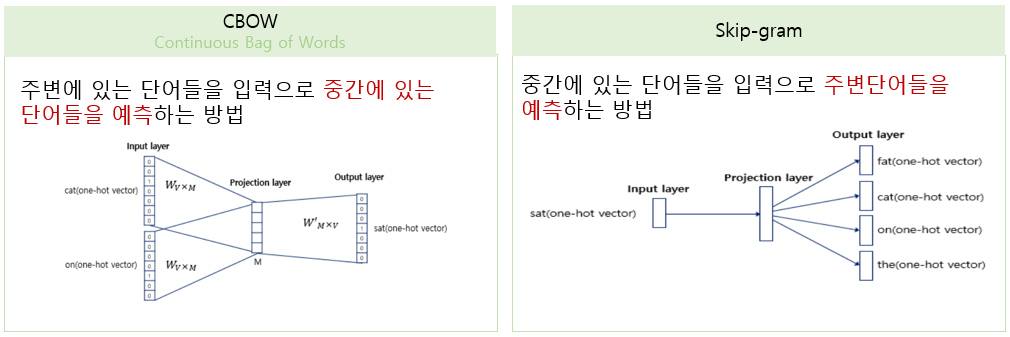

### 3. SGNS (Skip-Gram with Negative Sampling)
- SGNS(Skip-Gram with Negative Sampling)는 Skip-gram 모델의 변형으로, 단어 임베딩을 효율적으로 학습하기 위해 네거티브 샘플링(Negative Sampling) 기법을 사용합니다. 
- 기본 Skip-gram은 중심 단어로 주변의 모든 문맥 단어를 예측해야 하지만, 
- SGNS는 주변 단어와의 관계를 일부 샘플로만 학습하여 계산 비용을 줄입니다. 
- 즉, 중심 단어와 실제 문맥 단어 쌍(정답)을 학습하면서, 무작위로 선택된 단어(네거티브 샘플)들과의 관계를 "연관성이 없다"고 학습시킵니다. 
- 이를 통해 모델은 중심 단어와 문맥 단어 간의 의미적 관계를 효과적으로 학습하면서도 연산량을 크게 줄일 수 있습니다. 
- SGNS는 Word2Vec 알고리즘에서 널리 사용되며, 실제로 가장 보편적인 단어 임베딩 학습 방법으로 자리 잡았습니다.

> SGNS는 중심 단어와 문맥 단어의 의미적 관계를 학습하며 
>   - Positive Pair는 중심 단어와 문맥 단어의 Embedding Vector를 가까운 위치에 배치, 
>   - Negative Pair는 중심 단어와 연관 없는 단어의 벡터를 멀리 배치함

### 4. FastText
- [FastText](https://fasttext.cc/)는 Facebook AI Research(FAIR)에서 개발한 단어 임베딩 및 텍스트 분류 모델로, 
- Word2Vec과 유사하지만 서브워드(subword) 정보를 활용하여 더 강력한 성능을 제공합니다. 
- 기존의 단어 임베딩 기법들은 단어 단위로 벡터를 학습하지만, FastText는 단어를 여러 개의 n-그램 문자 조각(character n-grams)으로 분해하여 학습하기 때문에 희귀 단어(OOV, Out-of-Vocabulary) 처리와 형태소 기반 언어(예: 한국어)에서 뛰어난 성능을 보입니다. 
- 또한, FastText는 텍스트 분류에도 활용 가능하며, 빠른 속도와 높은 성능 덕분에 감성 분석, 문서 분류, 검색 시스템 등 다양한 자연어 처리(NLP) 작업에서 널리 사용됩니다.

### 영어에서의 처리 (예시 중심)

- 토큰화: 보통 공백 토큰화 + 소문자화 사용.
- n‑그램 길이: 보편적으로 3~6(minn=3, maxn=6).
- 예시: 단어 playing → 문자 3‑그램 일부: <pl, pla, lay, ayi, yin, ing, ng>
    - 접두/접미 경계 표시는 fastText 구현에서 자동으로 붙여줍니다(예: <와 >).
- 효과: play, played, playing, playful, playfulness는 많은 서브워드를 공유하므로 의미가 가까운 벡터가 됩니다.
- OOV 예시: 학습에 없던 playfulness도 play, lay, ful, ness 같은 서브워드로 벡터를 구성하므로 유사 단어 검색이 가능합니다.

### 한국어에서의 처리 (포인트와 예시)
- 한국어는 교착어라 어미·조사가 붙어 형태가 다양합니다(예: 행복, 행복하다, 행복했다, 행복하게).
- fastText는 문자 단위 n‑그램을 쓰므로, 형태가 달라도 공통 부분(“행복”, “강아지”)을 공유하면 유사한 벡터로 묶입니다.
- 토큰화 선택지
    - 간단: 띄어쓰기 기준 토큰화만 사용해도 subword 덕분에 어느 정도 해결됨.
    - 더 정확: 형태소 분석기(예: MeCab, Okt)로 ‘강아지/들+을’, ‘행복/하+다’처럼 쪼개면 품사·어미를 더 잘 반영
- n‑그램 길이 추천: 한글 음절 단위 특성상 minn=2~3, maxn=4~6 범위를 시도합니다(코퍼스와 길이에 따라 튜닝).

### 한국어에서의 자모 단위 n-그램
- 한국어 문자는 사실 초성(ㄱ/ㄴ/ㄷ…), 중성(ㅏ/ㅑ…), 종성(ㄱ/ㄴ/…)이 합쳐진 한글 음절 블록입니다.
- fastText는 이를 특별히 분해하지 않고 유니코드 음절 단위(가~힣) 그대로 n-그램을 만듭니다.
- 다만, 어떤 토크나이저/전처리기를 쓰느냐에 따라 자모 분해(normalize NFD)를 먼저 적용하면, 그 상태에서 fastText가 자모 단위 n-그램을 만드는 효과가 납니다.
- 유니코드 NFC(일반 표기): U+AC15 = "강" (1개 문자)
- NFD 정규화 후: ᄀ + ᅡ + ᆼ (자모 3개)
→ 이 경우 fastText는 "ᄀ", "ᅡ", "ᆼ"을 각각 문자로 보고 n-그램을 만들게 됩니다.